# Tarea 2: disponibilidad y evolución temporal de puntos de acceso wifi

Este notebook acompaña los cálculos de la Tarea 2. El desarrollo matemático y las interpretaciones deben quedar en el informe.

## Integrantes

- Enrique Manzano Ojeda — Rol USM: 202330530-8
- Nicolás Sepúlveda Lynch — Rol USM: 2023305171-0

## Uso

Complete los TODO, ejecute las celdas en orden y guarde el notebook con los resultados visibles.


## Bibliotecas necesarias

Si falta alguna biblioteca, instálela con:

```python
%pip install numpy matplotlib
```

## Sección 1.1 del enunciado: Diagrama y matriz de transición

Use el orden de estados $(F,D,O)$ indicado en el enunciado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

np.set_printoptions(precision=5, suppress=True)

orden_estados = ["F", "D", "O"]

# Permanencias dadas en el enunciado
p_ff = 0.70
p_dd = 0.60
p_oo = 0.85
# Desde F: lo que sale es 0.30 y F->O = 2*(F->D)  =>  3x = 0.30, x = 0.10
p_fd = (1 - p_ff) / 3          # 0.10
p_fo = 2 * (1 - p_ff) / 3      # 0.20
# Desde D: lo que sale es 0.40 y D->O = 7*(D->F)  =>  8x = 0.40, x = 0.05
p_df = (1 - p_dd) / 8          # 0.05
p_do = 7 * (1 - p_dd) / 8      # 0.35
# Desde O: lo que sale es 0.15 y O->D = 2*(O->F)  =>  3x = 0.15, x = 0.05
p_of = (1 - p_oo) / 3          # 0.05
p_od = 2 * (1 - p_oo) / 3      # 0.10

P = np.array([
    [p_ff, p_fd, p_fo],
    [p_df, p_dd, p_do],
    [p_of, p_od, p_oo],
], dtype=float)

print("Orden de estados:", orden_estados)
print("Matriz P:\n", P)
print("Probabilidades entre cero y uno:", np.all((P >= 0) & (P <= 1)))
print("Suma de cada fila:", P.sum(axis=1))
print("Las filas suman uno:", np.allclose(P.sum(axis=1), 1))
print("F a O:", P[0, 2])
print("O a F:", P[2, 0])

Orden de estados: ['F', 'D', 'O']
Matriz P:
 [[0.7  0.1  0.2 ]
 [0.05 0.6  0.35]
 [0.05 0.1  0.85]]
Probabilidades entre cero y uno: True
Suma de cada fila: [1. 1. 1.]
Las filas suman uno: True
F a O: 0.20000000000000004
O a F: 0.05000000000000001


## Sección 1.2 del enunciado: Distribución transiente y disponibilidad

Use el orden $(F,D,O)$ y el criterio de disponibilidad del enunciado.

In [2]:
alpha_0 = np.array([0.0, 0.0, 1.0])
alpha_1 = alpha_0 @ P # @ representa multiplicación matricial
alpha_2 = alpha_1 @ P
dias = np.arange(1, 31)
alpha_evolucion = np.array([
    alpha_0 @ np.linalg.matrix_power(P, int(dia)) # matrix_power -> P^n
    for dia in dias
])
alpha_7 = alpha_evolucion[6]
alpha_30 = alpha_evolucion[29]

# TODO: indique con cero o uno si cada estado entrega conectividad.
# Para ello defínalo en la variable indicador_conectividad como un vector (lista python) 
indicador_conectividad = [0, 1, 1]  # F no entrega; D y O si entregan
indicador_conectividad = np.asarray(indicador_conectividad, dtype=float)

disponibilidad_ap = alpha_evolucion @ indicador_conectividad

print("alpha_1:", alpha_1)
print("alpha_2:", alpha_2)
print("alpha_7:", alpha_7)
print("alpha_30:", alpha_30)
for dia in [1, 2, 7, 30]:
    print(f"Disponibilidad en el día {dia}: {disponibilidad_ap[dia - 1]:.6f}")

alpha_1: [0.05 0.1  0.85]
alpha_2: [0.0825 0.15   0.7675]
alpha_7: [0.13585 0.19844 0.66571]
alpha_30: [0.14286 0.2     0.65714]
Disponibilidad en el día 1: 0.950000
Disponibilidad en el día 2: 0.917500
Disponibilidad en el día 7: 0.864146
Disponibilidad en el día 30: 0.857143


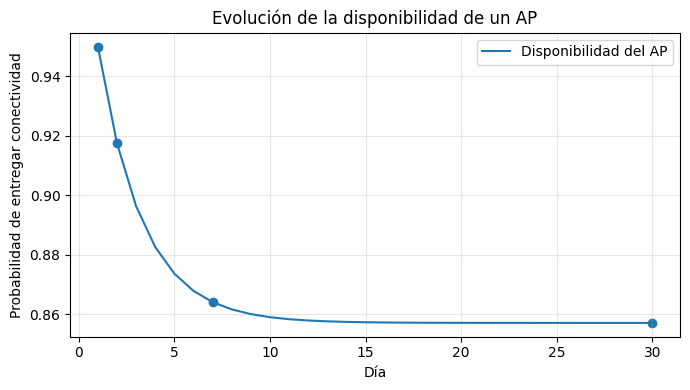

In [3]:
plt.figure(figsize=(7, 4))
plt.plot(dias, disponibilidad_ap, label="Disponibilidad del AP")
plt.scatter([1, 2, 7, 30], [disponibilidad_ap[0], disponibilidad_ap[1], disponibilidad_ap[6], disponibilidad_ap[29]])
plt.xlabel("Día")
plt.ylabel("Probabilidad de entregar conectividad")
plt.title("Evolución de la disponibilidad de un AP")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Evolución de los estados del AP

Gráfico adicional solicitado en la Sección 5 del enunciado: probabilidad de cada estado $(F,D,O)$ desde el día 0 al 30.

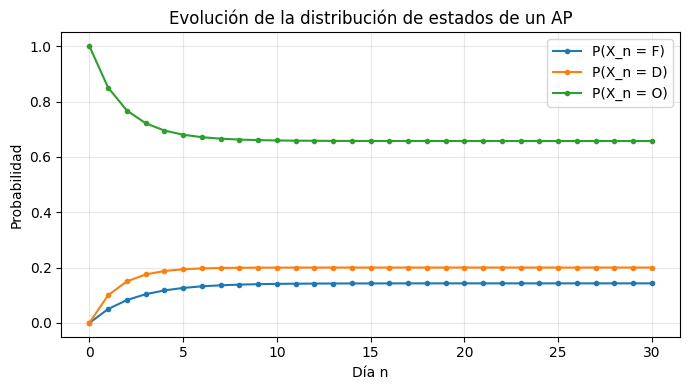

In [4]:
dias_0 = np.arange(0, 31)
alpha_todos = np.array([alpha_0 @ np.linalg.matrix_power(P, int(d)) for d in dias_0])

plt.figure(figsize=(7, 4))
for j, nombre in enumerate(orden_estados):
    plt.plot(dias_0, alpha_todos[:, j], marker=".", label=f"P(X_n = {nombre})")
plt.xlabel("Día n")
plt.ylabel("Probabilidad")
plt.title("Evolución de la distribución de estados de un AP")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Sección 2.1 del enunciado: Primera visita y primer retorno

Parta desde el estado $O$.

In [5]:
P_dos_pasos = np.linalg.matrix_power(P, 2)

# TODO: sume las probabilidades de las rutas de primera visita a F.
# Indique en el informe las rutas utilizadas y en el jupyter notebook a cuál
# ruta corresponde cada variable 
ruta_of1 = P[2, 1] * P[1, 0]   # ruta O -> D -> F
ruta_of2 = P[2, 2] * P[2, 0]   # ruta O -> O -> F
primera_visita_f_dos = ruta_of1 + ruta_of2
# Se excluye O -> F -> F porque ya visito F en el paso 1

# TODO: sume las probabilidades de las rutas de primer retorno a O.
# Indique en el informe las rutas utilizadas y en el jupyter notebook a cuál
# ruta corresponde cada variable
ruta_oo1 = P[2, 0] * P[0, 2]   # ruta O -> F -> O
ruta_oo2 = P[2, 1] * P[1, 2]   # ruta O -> D -> O
primer_retorno_o_dos = ruta_oo1 + ruta_oo2
# Se excluye O -> O -> O porque ya retorno a O en el paso 1

print("Primera visita a F en el paso 2:", primera_visita_f_dos)
print("Entrada correspondiente de P al cuadrado:", P_dos_pasos[2, 0])
print("Primer retorno a O en el paso 2:", primer_retorno_o_dos)
print("Entrada de O a O en P al cuadrado:", P_dos_pasos[2, 2])

Primera visita a F en el paso 2: 0.047500000000000014
Entrada correspondiente de P al cuadrado: 0.08250000000000002
Primer retorno a O en el paso 2: 0.04500000000000001
Entrada de O a O en P al cuadrado: 0.7675


In [6]:
pasos = np.arange(1, 31)
prob_en_f = np.array([np.linalg.matrix_power(P, int(n))[2, 0] for n in pasos])
primera_visita_f = np.zeros(len(pasos))

for n in pasos:
    suma_rutas_anteriores = 0.0
    # NOTE: El siguiente código debe implementar lo visto en la slide "Relación recursiva para primera visita", presentación 04
    for k in range(1, n):
        prob_permanece_f = np.linalg.matrix_power(P, int(n - k))[0, 0]
        # f_OF^(k) * p_FF^(n-k): primera llegada a F en el paso k y luego estar en F en el paso n
        suma_rutas_anteriores += primera_visita_f[k - 1] * prob_permanece_f
    primera_visita_f[n - 1] = prob_en_f[n - 1] - suma_rutas_anteriores

print("Probabilidad de estar en F después de 30 días:", prob_en_f[-1])
print("Probabilidad de primera visita a F en el día 30:", primera_visita_f[-1])

Probabilidad de estar en F después de 30 días: 0.14285679427698733
Probabilidad de primera visita a F en el día 30: 0.011296777049628282


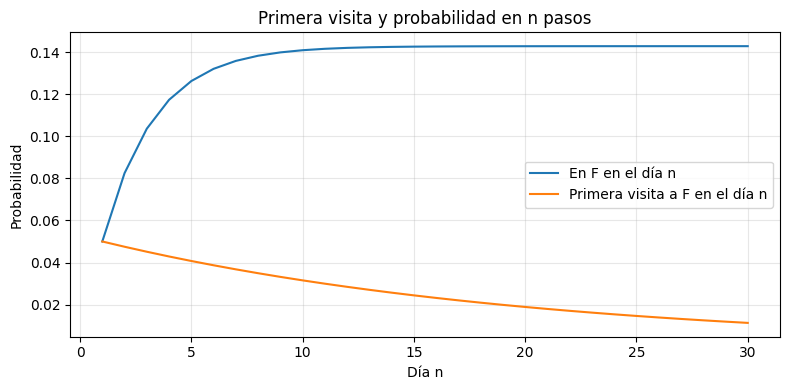

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(pasos, prob_en_f, label="En F en el día n")
plt.plot(pasos, primera_visita_f, label="Primera visita a F en el día n")
plt.xlabel("Día n")
plt.ylabel("Probabilidad")
plt.title("Primera visita y probabilidad en n pasos")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Sección 2.2 del enunciado: Distribución estacionaria

Use el criterio de servicio de la Pregunta 1.

In [8]:
sistema_pi = P.T - np.eye(3)
sistema_pi[-1, :] = 1.0
termino_derecho = np.array([0.0, 0.0, 1.0])
pi_ap = np.linalg.solve(sistema_pi, termino_derecho)
disponibilidad_estacionaria_ap = pi_ap @ indicador_conectividad

print("Distribución estacionaria del AP:", pi_ap)
print("Verificación pi por P:", pi_ap @ P)
print("Disponibilidad estacionaria del AP:", disponibilidad_estacionaria_ap)
print("Disponibilidad en el día 30:", disponibilidad_ap[29])

Distribución estacionaria del AP: [0.14286 0.2     0.65714]
Verificación pi por P: [0.14286 0.2     0.65714]
Disponibilidad estacionaria del AP: 0.8571428571428572
Disponibilidad en el día 30: 0.8571432057230125


## Sección 3 del enunciado: Extensión a cinco AP

Complete los valores de $p$ y $r$.

In [9]:
# TODO: complete p y r según lo indicado en el enunciado.
# C = {D, O}. Desde D y desde O la probabilidad de pasar a F es la misma (0.05),
# por lo que p no depende de en cual estado disponible se encuentre el AP.
p = P[1, 0]                    # = P[2, 0] = 0.05
assert np.isclose(P[1, 0], P[2, 0])
# Desde F, volver a entregar conectividad es ir a D o a O
r = P[0, 1] + P[0, 2]          # 0.10 + 0.20 = 0.30
print("p:", p)
print("r:", r)

p: 0.05
r: 0.30000000000000004


### Sección 3.2 del enunciado: Disponibilidad de la red

Calcule las disponibilidades transiente y estacionaria de la red.

In [10]:
numero_ap = 5
P_cinco = np.zeros((numero_ap + 1, numero_ap + 1))

for disponibles_hoy in range(numero_ap + 1):
    for sobreviven in range(disponibles_hoy + 1):
        prob_sobreviven = (
            comb(disponibles_hoy, sobreviven)
            * (1 - p) ** sobreviven
            * p ** (disponibles_hoy - sobreviven)
        )
        for se_recuperan in range(numero_ap - disponibles_hoy + 1):
            prob_recuperacion = (
                comb(numero_ap - disponibles_hoy, se_recuperan)
                * r ** se_recuperan
                * (1 - r) ** (numero_ap - disponibles_hoy - se_recuperan)
            )
            disponibles_manana = sobreviven + se_recuperan
            P_cinco[disponibles_hoy, disponibles_manana] += prob_sobreviven * prob_recuperacion

print("Suma de cada fila:", P_cinco.sum(axis=1))
print("Las filas suman uno:", np.allclose(P_cinco.sum(axis=1), 1))
print("Matriz de transición para cinco AP:", P_cinco)

Suma de cada fila: [1. 1. 1. 1. 1. 1.]
Las filas suman uno: True
Matriz de transición para cinco AP: [[0.16807 0.36015 0.3087  0.1323  0.02835 0.00243]
 [0.012   0.24867 0.40425 0.25515 0.07223 0.0077 ]
 [0.00086 0.03369 0.35192 0.41602 0.17314 0.02437]
 [0.00006 0.00354 0.06934 0.47761 0.37228 0.07716]
 [0.      0.00033 0.00962 0.12409 0.6216  0.24435]
 [0.      0.00003 0.00113 0.02143 0.20363 0.77378]]


In [11]:
alpha_cinco_0 = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 1.0])
alpha_cinco_30 = alpha_cinco_0 @ np.linalg.matrix_power(P_cinco, 30)

sistema_pi_cinco = P_cinco.T - np.eye(numero_ap + 1)
sistema_pi_cinco[-1, :] = 1.0
termino_cinco = np.zeros(numero_ap + 1)
termino_cinco[-1] = 1.0
pi_cinco = np.linalg.solve(sistema_pi_cinco, termino_cinco)

disponibilidad_red_30 = alpha_cinco_30[3:].sum()
disponibilidad_red_estacionaria = pi_cinco[3:].sum()

print("Distribución en el día 30:", alpha_cinco_30)
print("Distribución estacionaria:", pi_cinco)
print("Disponibilidad de la red en el día 30:", disponibilidad_red_30)
print("Disponibilidad estacionaria de la red:", disponibilidad_red_estacionaria)

Distribución en el día 30: [0.00006 0.00178 0.02142 0.12852 0.38555 0.46267]
Distribución estacionaria: [0.00006 0.00178 0.02142 0.12852 0.38555 0.46266]
Disponibilidad de la red en el día 30: 0.9767360406533292
Disponibilidad estacionaria de la red: 0.9767358838579164


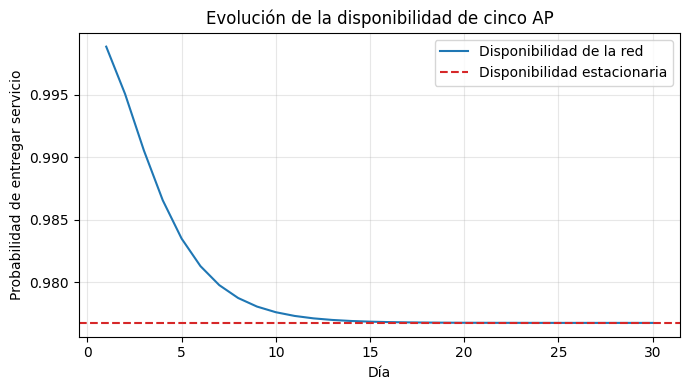

In [12]:
distribuciones_cinco = np.array([
    alpha_cinco_0 @ np.linalg.matrix_power(P_cinco, int(dia))
    for dia in dias
])
disponibilidad_red = distribuciones_cinco[:, 3:].sum(axis=1)

plt.figure(figsize=(7, 4))
plt.plot(dias, disponibilidad_red, label="Disponibilidad de la red")
plt.axhline(disponibilidad_red_estacionaria, color="tab:red", linestyle="--", label="Disponibilidad estacionaria")
plt.xlabel("Día")
plt.ylabel("Probabilidad de entregar servicio")
plt.title("Evolución de la disponibilidad de cinco AP")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Apoyo a la Sección 4 (verificación numérica)

El desarrollo de la Sección 4 está en el informe; esta celda solo verifica los números.

In [13]:
from math import exp

# 4.1 Binomial con q30 obtenido de la DTMC de un AP (estados D y O)
q30 = alpha_30[1] + alpha_30[2]
prob_binomial_al_menos_3 = sum(comb(5, k) * q30**k * (1 - q30)**(5 - k) for k in range(3, 6))
print("q30:", q30)
print("Binomial P(Z30 >= 3):", prob_binomial_al_menos_3)
print("DTMC de cinco AP, A30:", disponibilidad_red_30)

# 4.2 Weibull sin reparación
beta, eta, t_mision = 3.0, 226.0, 30.0
R30 = exp(-(t_mision / eta) ** beta)
R_red = sum(comb(5, k) * R30**k * (1 - R30)**(5 - k) for k in range(3, 6))
print("R(30) de un AP:", R30)
print("P(al menos 3 de 5 sobreviven):", R_red)

q30: 0.8571432057230125
Binomial P(Z30 >= 3): 0.9767360406533359
DTMC de cinco AP, A30: 0.9767360406533292
R(30) de un AP: 0.9976636891348042
P(al menos 3 de 5 sobreviven): 0.9999998729224978
